# Install packages

In [1]:
!pip install plotly # for interactive plots
!pip install -U kaleido # to save interacive plots as static images
!yes | plotly_get_chrome

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [kaleido]m5/6 [kaleido]

Plotly will install a copy of Google Chrome to be used for generating static images of plots.
Chrome will be installed at: None
Do you want to proceed? [y/n] Installing Chrome for Plotly...
Chrome installed successfully.
The Chrome executable is now located at: /home/ec2-user/anaconda3/envs/pytorch_p310/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
yes: standard output: Broken pipe
yes: write error


# Load dependencies

In [2]:
import numpy as np
import pandas as pd

# Machine learning and dimensionality reduction
from sklearn.manifold import TSNE

# PyTorch for loading embeddings
import torch

# File system operations
import os

# Interactive plotting with Plotly
import plotly.graph_objects as go
import plotly.colors  # For color palettes (fallback)

# Optional: For enhanced color sampling (if available)
try:
    from plotly.colors import sample_colorscale
except ImportError:
    print("Note: sample_colorscale not available, using fallback colors")

/home/ec2-user/anaconda3/envs/pytorch_p310/lib/python3.10/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


# Inputs

In [3]:
label_subset = ['ShCAST_L46I', 'ShCAST_L46F', 'ShCAST_E188A', 'ShCAST_E188C', 'ShCAST_G135P', 'ShCAST_L113H', 'ShCAST_E238W', 'ShCAST_V58C', 'ShCAST_V92T', 'ShCAST_I94T', 'ShCAST_F196Q', 'ShCAST_E145Q', 'ShCAST_R116I_S200L']
exclude_subset = ['ShCAST_M1A', 'ShCAST_M1C', 'ShCAST_M1D', 'ShCAST_M1E', 'ShCAST_M1F', 'ShCAST_M1G', 'ShCAST_M1H', 'ShCAST_M1I', 'ShCAST_M1K', 'ShCAST_M1L', 'ShCAST_M1N', 'ShCAST_M1P', 'ShCAST_M1Q', 'ShCAST_M1R', 'ShCAST_M1S', 'ShCAST_M1T', 'ShCAST_M1V', 'ShCAST_M1W', 'ShCAST_M1Y']

# Visualize ESM2 sequence embeddings using tSNE

## Function

In [4]:
def visualize_embeddings_tsne(
    directory_path,
    perplexity=30,
    learning_rate="auto",
    n_iterations=1000, 
    fontsize=12,
    text_alpha=0.7,
    output_path='tsne_visualization.png',
    csv_path=None,
    name_column=None,
    value_column=None,
    colormap='viridis',
    categorical_colorscale=None,
    show_colorbar=True,
    show_legend=True, 
    marker_size=8,
    width=1000,
    height=700,
    fig_title=None,
    label_subset=None,
    colored_marker_size=None,
    colored_marker_alpha=0.8,
    exclude_labels=None,
    output_html=None           # ← NEW PARAMETER
):
    """
    Perform t-SNE visualization on embeddings from .pt files in a given directory,
    with optional coloring based on values from a CSV file. Creates interactive plots with Plotly.
    All embeddings are shown as pale gray points, with CSV-matched points colored on top.
    If output_html is provided, saves an interactive HTML with a search bar that highlights
    matching points in red at the topmost layer.
    """

    import os
    import numpy as np
    import pandas as pd
    import torch
    from sklearn.manifold import TSNE
    import plotly.graph_objects as go
    
    # Validate and ensure minimum font size
    fontsize = max(1, int(fontsize))
    
    # Set colored marker size to marker_size if not specified
    if colored_marker_size is None:
        colored_marker_size = marker_size
    
    # Validate alpha value
    colored_marker_alpha = max(0.0, min(1.0, float(colored_marker_alpha)))
    
    # Collect all embeddings and their labels
    embeddings = []
    labels = []
    
    # Normalize exclude_labels to a set for fast lookup
    if exclude_labels is None:
        exclude_set = set()
    else:
        exclude_set = set(exclude_labels)

    # Iterate through .pt files in the directory
    for filename in os.listdir(directory_path):
        if filename.endswith('.pt'):
            file_path = os.path.join(directory_path, filename)
            base_filename = os.path.splitext(filename)[0]

            if base_filename in exclude_set:
                continue

            try:
                embedding = torch.load(file_path)
                
                if isinstance(embedding, torch.Tensor):
                    if embedding.is_cuda:
                        embedding = embedding.cpu()
                    
                    if embedding.dim() > 1:
                        embedding = embedding.squeeze()
                    
                    embedding = embedding.detach().numpy()
                
                embedding = embedding.flatten()
                
                embeddings.append(embedding)
                labels.append(base_filename)
            
            except Exception as e:
                print(f"Error processing {filename}: {e}")
    
    if len(embeddings) == 0:
        print("No valid embeddings found in directory")
        return
    
    embeddings = np.array(embeddings)
    
    tsne = TSNE(
        n_components=2, 
        perplexity=min(perplexity, len(embeddings) - 1), 
        learning_rate=learning_rate, 
        max_iter=n_iterations,
        random_state=42,
        metric='cosine'
    )
    
    tsne_coords = tsne.fit_transform(embeddings)
    
    color_values = None
    color_labels = None
    is_categorical = False
    matched_indices = []
    
    if csv_path and name_column and value_column:
        try:
            df = pd.read_csv(csv_path, dtype={name_column: str})
            df[value_column] = pd.to_numeric(df[value_column], errors='coerce')
            
            numeric_count = df[value_column].notna().sum()
            total_count = len(df)
            
            if numeric_count / total_count < 0.5:
                df = pd.read_csv(csv_path, dtype={name_column: str, value_column: str})
                is_categorical = True
                print(f"Treating '{value_column}' as categorical data")
            else:
                is_categorical = False
                print(f"Treating '{value_column}' as numerical data ({numeric_count}/{total_count} valid numeric values)")
            
            name_to_value = dict(zip(df[name_column], df[value_column]))
            
            valid_color_values = []
            valid_color_labels = []
            
            for i, label in enumerate(labels):
                matched_value = None
                if label in name_to_value:
                    matched_value = name_to_value[label]
                elif f"ShCAST_{label}" in name_to_value:
                    matched_value = name_to_value[f"ShCAST_{label}"]
                elif label.startswith("ShCAST_"):
                    stripped_label = label[7:]
                    if stripped_label in name_to_value:
                        matched_value = name_to_value[stripped_label]
                
                if matched_value is not None and pd.notna(matched_value):
                    valid_color_values.append(matched_value)
                    valid_color_labels.append(matched_value)
                    matched_indices.append(i)
            
            if matched_indices:
                color_values = np.array(valid_color_values)
                
                if not is_categorical:
                    color_labels = None
                else:
                    color_labels = [str(val) for val in valid_color_labels]
                
                print(
                    f"Found {len(matched_indices)} matches between embeddings and CSV data "
                    f"out of {len(labels)} total embeddings"
                )
            else:
                print("No matches found between embeddings and CSV data")
                color_values = None
                matched_indices = []
        
        except Exception as e:
            print(f"Error processing CSV file: {e}")
            color_values = None
            matched_indices = []
    
    def should_show_label(label_name):
        if label_subset is None:
            return True
        elif isinstance(label_subset, list) and len(label_subset) == 0:
            return False
        elif isinstance(label_subset, list):
            return label_name in label_subset
        else:
            return True
    
    def get_categorical_colors(unique_labels, categorical_colorscale):
        n_categories = len(unique_labels)
        import plotly.colors as pc
        
        if categorical_colorscale is None:
            return (
                pc.qualitative.Plotly[:n_categories]
                if n_categories <= len(pc.qualitative.Plotly)
                else pc.qualitative.Plotly * ((n_categories // len(pc.qualitative.Plotly)) + 1)
            )
        elif isinstance(categorical_colorscale, list):
            if len(categorical_colorscale) >= n_categories:
                return categorical_colorscale[:n_categories]
            else:
                return (
                    categorical_colorscale
                    * ((n_categories // len(categorical_colorscale)) + 1)
                )[:n_categories]
        elif isinstance(categorical_colorscale, str):
            try:
                import plotly.colors as pc
                colorscale = getattr(pc.qualitative, categorical_colorscale, None)
                if colorscale is not None:
                    return (
                        colorscale[:n_categories]
                        if n_categories <= len(colorscale)
                        else colorscale * ((n_categories // len(colorscale)) + 1)
                    )
                else:
                    print(f"Warning: Could not find colorscale '{categorical_colorscale}', using default colors")
                    return (
                        pc.qualitative.Plotly[:n_categories]
                        if n_categories <= len(pc.qualitative.Plotly)
                        else pc.qualitative.Plotly * ((n_categories // len(pc.qualitative.Plotly)) + 1)
                    )
            except Exception as e:
                print(f"Warning: Error with colorscale '{categorical_colorscale}': {e}, using default colors")
                import plotly.colors as pc
                return (
                    pc.qualitative.Plotly[:n_categories]
                    if n_categories <= len(pc.qualitative.Plotly)
                    else pc.qualitative.Plotly * ((n_categories // len(pc.qualitative.Plotly)) + 1)
                )
        else:
            import plotly.colors as pc
            return (
                pc.qualitative.Plotly[:n_categories]
                if n_categories <= len(pc.qualitative.Plotly)
                else pc.qualitative.Plotly * ((n_categories // len(pc.qualitative.Plotly)) + 1)
            )
    
    fig = go.Figure()
    
    title = f't-SNE Visualization'
    if fig_title:
        title = f't-SNE Visualization: {fig_title}'
    title += f'<br>(Perplexity={perplexity}, LR={learning_rate}, Iterations={n_iterations})'
    if csv_path and value_column and matched_indices:
        title += (
            f'<br>Colored by: {value_column} '
            f'({len(matched_indices)}/{len(labels)} points colored)'
        )
    
    matched_set = set(matched_indices) if matched_indices else set()
    
    # Base layer: unmatched embeddings (gray background)
    unmatched_indices = [i for i in range(len(labels)) if i not in matched_set]
    if unmatched_indices:
        unmatched_coords = tsne_coords[unmatched_indices]
        unmatched_labels = [labels[i] for i in unmatched_indices]
        
        fig.add_trace(go.Scatter(
            x=unmatched_coords[:, 0],
            y=unmatched_coords[:, 1],
            mode='markers',
            marker=dict(
                size=marker_size,
                color='lightgray',
                opacity=0.4,
                line=dict(width=0)
            ),
            customdata=unmatched_labels,
            hovertemplate='<b>%{customdata}</b><br>x: %{x:.2f}<br>y: %{y:.2f}<extra></extra>',
            name='Unlabelled embeddings',
            showlegend=True
        ))
    
    # Colored overlay for matched embeddings
    if color_values is not None and matched_indices:
        matched_coords = tsne_coords[matched_indices]
        matched_labels = [labels[i] for i in matched_indices]
        
        if is_categorical and color_labels is not None:
            try:
                unique_cat_labels = sorted(list(set(color_labels)))
            except TypeError:
                unique_cat_labels = list(set(color_labels))
            
            colors = get_categorical_colors(unique_cat_labels, categorical_colorscale)
            
            for i, category in enumerate(unique_cat_labels):
                category_mask = [color_labels[j] == category for j in range(len(color_labels))]
                category_indices = [matched_indices[j] for j, m in enumerate(category_mask) if m]
                if category_indices:
                    category_coords = tsne_coords[category_indices]
                    category_hover_labels = [matched_labels[j] for j, m in enumerate(category_mask) if m]
                    
                    fig.add_trace(go.Scatter(
                        x=category_coords[:, 0],
                        y=category_coords[:, 1],
                        mode='markers',
                        marker=dict(
                            size=colored_marker_size,
                            color=colors[i] if i < len(colors) else colors[0],
                            opacity=colored_marker_alpha,
                            line=dict(width=0.5, color='white')
                        ),
                        name=str(category),
                        customdata=category_hover_labels,
                        hovertemplate=(
                            f'<b>%{{customdata}}</b><br>{value_column}: {category}'
                            '<br>x: %{x:.2f}<br>y: %{y:.2f}<extra></extra>'
                        ),
                        showlegend=show_legend
                    ))
        else:
            fig.add_trace(go.Scatter(
                x=matched_coords[:, 0],
                y=matched_coords[:, 1],
                mode='markers',
                marker=dict(
                    size=colored_marker_size,
                    color=color_values,
                    colorscale=colormap,
                    colorbar=dict(title=value_column) if show_colorbar else None,
                    opacity=colored_marker_alpha,
                    showscale=show_colorbar,
                    line=dict(width=0.5, color='white')
                ),
                customdata=matched_labels,
                hovertemplate=(
                    f'<b>%{{customdata}}</b><br>{value_column}: %{{marker.color}}'
                    '<br>x: %{x:.2f}<br>y: %{y:.2f}<extra></extra>'
                ),
                name=f'Colored by {value_column}',
                showlegend=show_legend
            ))
    
    fig.update_layout(
        title=dict(
            text=title,
            x=0.5,
            font=dict(size=16)
        ),
        xaxis_title='t-SNE Dimension 1',
        yaxis_title='t-SNE Dimension 2',
        width=width,
        height=height,
        showlegend=show_legend,
        legend=dict(
            orientation="v",
            yanchor="top",
            y=1,
            xanchor="left",
            x=1.02
        ),
        margin=dict(l=50, r=150 if show_legend else 50, t=100, b=50),
        hovermode='closest',
        plot_bgcolor='white',
        paper_bgcolor='white',
        xaxis=dict(
            showgrid=False,
            linecolor='black',
            showline=True,
            zeroline=False
        ),
        yaxis=dict(
            showgrid=False,
            linecolor='black',
            showline=True,
            zeroline=False
        )
    )
    
    # Annotations
    annotation_count = 0
    for label, x_coord, y_coord in zip(labels, tsne_coords[:, 0], tsne_coords[:, 1]):
        if should_show_label(label):
            display_text = label.split('_', 1)[-1] if '_' in label else label
            
            fig.add_annotation(
                x=x_coord,
                y=y_coord,
                text=str(display_text),
                showarrow=True,
                arrowhead=2,
                arrowsize=1,
                arrowwidth=1,
                arrowcolor="black",
                ax=0,
                ay=-10,
                font=dict(
                    size=max(8, fontsize),
                    color="black",
                    family="Arial"
                ),
                bgcolor="white",
                bordercolor="black",
                borderwidth=1,
                xanchor="center",
                yanchor="bottom"
            )
            annotation_count += 1
    
    print(f"Added {annotation_count} label annotations to the plot")
    if annotation_count == 0:
        print("No labels to display based on label_subset parameter")
        if label_subset is not None:
            print(f"Available labels: {labels[:10]}...")
            print(f"Label subset requested: {label_subset}")
    
    # Save coordinates to CSV
    csv_output_path = output_path.rsplit('.', 1)[0] + '.csv'
    coords_df = pd.DataFrame({
        'embedding_name': labels,
        'tsne_x': tsne_coords[:, 0],
        'tsne_y': tsne_coords[:, 1]
    })
    
    if color_values is not None and matched_indices:
        coords_df[value_column] = pd.NA
        if is_categorical:
            for i, matched_idx in enumerate(matched_indices):
                coords_df.loc[matched_idx, value_column] = color_labels[i]
        else:
            for i, matched_idx in enumerate(matched_indices):
                coords_df.loc[matched_idx, value_column] = color_values[i]
    
    try:
        coords_df.to_csv(csv_output_path, index=False)
        print(f"t-SNE coordinates saved to: {csv_output_path}")
    except Exception as e:
        print(f"Warning: Could not save CSV file: {e}")
    
    fig.show()
    
    try:
        fig.write_image(output_path, width=width, height=height, scale=2)
        print(f"Static plot saved to: {output_path}")
    except Exception as e:
        print(f"Warning: Could not save PNG image: {e}")
        print("Note: You may need to install kaleido for image export: pip install kaleido")

    # ── NEW: Interactive HTML export with search bar ──────────────────────────
    if output_html:
        _save_html_with_search(
            fig=fig,
            labels=labels,
            tsne_coords=tsne_coords,
            output_html=output_html,
            marker_size=marker_size,
            width=width,
            height=height,
        )


def _save_html_with_search(fig, labels, tsne_coords, output_html, marker_size, width, height):
    """
    Writes the Plotly figure to an HTML file and injects a search bar UI.

    The search bar lets users type a query (substring match, case-insensitive)
    and immediately highlights all matching points as large red markers rendered
    in a dedicated top-layer Plotly trace, so they are never occluded.

    Implementation notes
    --------------------
    * The full label list and t-SNE coordinates are serialised as a JSON literal
      and embedded directly in the HTML so the page is fully self-contained.
    * On every keystroke the JS rebuilds the 'Search highlights' trace via
      Plotly.restyle, which is fast even for tens of thousands of points.
    * The highlight trace is always the last trace (highest z-order in Plotly).
    """
    import json
    import plotly.io as pio

    # Serialise the figure to HTML (no <html>/<body> wrapper yet)
    plot_div = pio.to_html(
        fig,
        full_html=False,
        include_plotlyjs='cdn',
        config={'responsive': True},
        div_id='tsne-plot'
    )

    # Build JSON payloads embedded in the page
    labels_json = json.dumps(labels)
    x_json = json.dumps(tsne_coords[:, 0].tolist())
    y_json = json.dumps(tsne_coords[:, 1].tolist())
    highlight_marker_size = max(marker_size * 2, 14)

    search_js = f"""
<script>
(function () {{
    // ── data embedded at render time ──────────────────────────────────────────
    const ALL_LABELS  = {labels_json};
    const ALL_X       = {x_json};
    const ALL_Y       = {y_json};
    const HIGHLIGHT_SIZE = {highlight_marker_size};

    // ── locate the Plotly div ─────────────────────────────────────────────────
    const plotDiv = document.getElementById('tsne-plot');

    // Plotly may not be ready immediately when using the CDN <script> tag.
    // Poll until the div has been initialised as a Plotly chart.
    function waitForPlotly(callback) {{
        if (plotDiv && plotDiv.data) {{
            callback();
        }} else {{
            setTimeout(function () {{ waitForPlotly(callback); }}, 100);
        }}
    }}

    waitForPlotly(function () {{
        // Add a permanent empty highlight trace as the LAST (topmost) trace.
        Plotly.addTraces(plotDiv, {{
            type: 'scatter',
            x: [],
            y: [],
            mode: 'markers',
            marker: {{
                color: 'red',
                size: HIGHLIGHT_SIZE,
                opacity: 1.0,
                line: {{ width: 1.5, color: 'darkred' }}
            }},
            customdata: [],
            hovertemplate: '<b>%{{customdata}}</b><br>x: %{{x:.2f}}<br>y: %{{y:.2f}}<extra>Search match</extra>',
            name: 'Search highlights',
            showlegend: true
        }});

        // Index of the highlight trace (always last)
        function highlightTraceIndex() {{
            return plotDiv.data.length - 1;
        }}

        // ── search handler ────────────────────────────────────────────────────
        function runSearch(query) {{
            const q = query.trim().toLowerCase();
            let matchX = [], matchY = [], matchLabels = [];

            if (q.length > 0) {{
                for (let i = 0; i < ALL_LABELS.length; i++) {{
                    if (ALL_LABELS[i].toLowerCase().includes(q)) {{
                        matchX.push(ALL_X[i]);
                        matchY.push(ALL_Y[i]);
                        matchLabels.push(ALL_LABELS[i]);
                    }}
                }}
            }}

            const idx = highlightTraceIndex();
            Plotly.restyle(plotDiv, {{
                x: [matchX],
                y: [matchY],
                customdata: [matchLabels]
            }}, idx);

            // Update match counter
            const counter = document.getElementById('search-counter');
            if (counter) {{
                counter.textContent = q.length === 0
                    ? ''
                    : matchX.length === 0
                        ? 'No matches'
                        : `${{matchX.length}} match${{matchX.length === 1 ? '' : 'es'}}`;
            }}
        }}

        // ── wire up the input ─────────────────────────────────────────────────
        const searchInput = document.getElementById('tsne-search-input');
        const clearBtn    = document.getElementById('tsne-search-clear');

        searchInput.addEventListener('input', function () {{
            runSearch(this.value);
        }});

        clearBtn.addEventListener('click', function () {{
            searchInput.value = '';
            runSearch('');
            searchInput.focus();
        }});

        searchInput.focus();
    }});
}})();
</script>
"""

    search_bar_html = f"""
<style>
  #search-container {{
      display: flex;
      align-items: center;
      gap: 8px;
      font-family: Arial, sans-serif;
      margin: 10px auto;
      max-width: {width}px;
      padding: 0 8px;
  }}
  #search-label {{
      font-size: 14px;
      font-weight: bold;
      white-space: nowrap;
      color: #333;
  }}
  #tsne-search-input {{
      flex: 1;
      padding: 6px 10px;
      font-size: 14px;
      border: 1px solid #ccc;
      border-radius: 4px;
      outline: none;
      transition: border-color 0.2s;
  }}
  #tsne-search-input:focus {{
      border-color: #0077cc;
      box-shadow: 0 0 0 2px rgba(0,119,204,0.2);
  }}
  #tsne-search-clear {{
      padding: 6px 12px;
      font-size: 14px;
      cursor: pointer;
      border: 1px solid #ccc;
      border-radius: 4px;
      background: #f5f5f5;
      transition: background 0.2s;
  }}
  #tsne-search-clear:hover {{
      background: #e0e0e0;
  }}
  #search-counter {{
      font-size: 13px;
      color: #555;
      min-width: 80px;
  }}
</style>

<div id="search-container">
  <span id="search-label">&#128269; Search:</span>
  <input
      id="tsne-search-input"
      type="text"
      placeholder="Type to highlight points..."
      autocomplete="off"
      spellcheck="false"
  />
  <button id="tsne-search-clear">Clear</button>
  <span id="search-counter"></span>
</div>
"""

    full_html = f"""<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <title>t-SNE Visualization</title>
</head>
<body style="margin:0; padding:8px; background:#fff;">
  {search_bar_html}
  {plot_div}
  {search_js}
</body>
</html>
"""

    try:
        with open(output_html, 'w', encoding='utf-8') as f:
            f.write(full_html)
        print(f"Interactive HTML saved to: {output_html}")
    except Exception as e:
        print(f"Warning: Could not save HTML file: {e}")


## Run

### Activity (transposition efficiency log2FC)

Treating 'log2FC' as numerical data (4352/4352 valid numeric values)
Found 4351 matches between embeddings and CSV data out of 5226 total embeddings
Added 13 label annotations to the plot
t-SNE coordinates saved to: assets/tsne_visualization_activity.csv


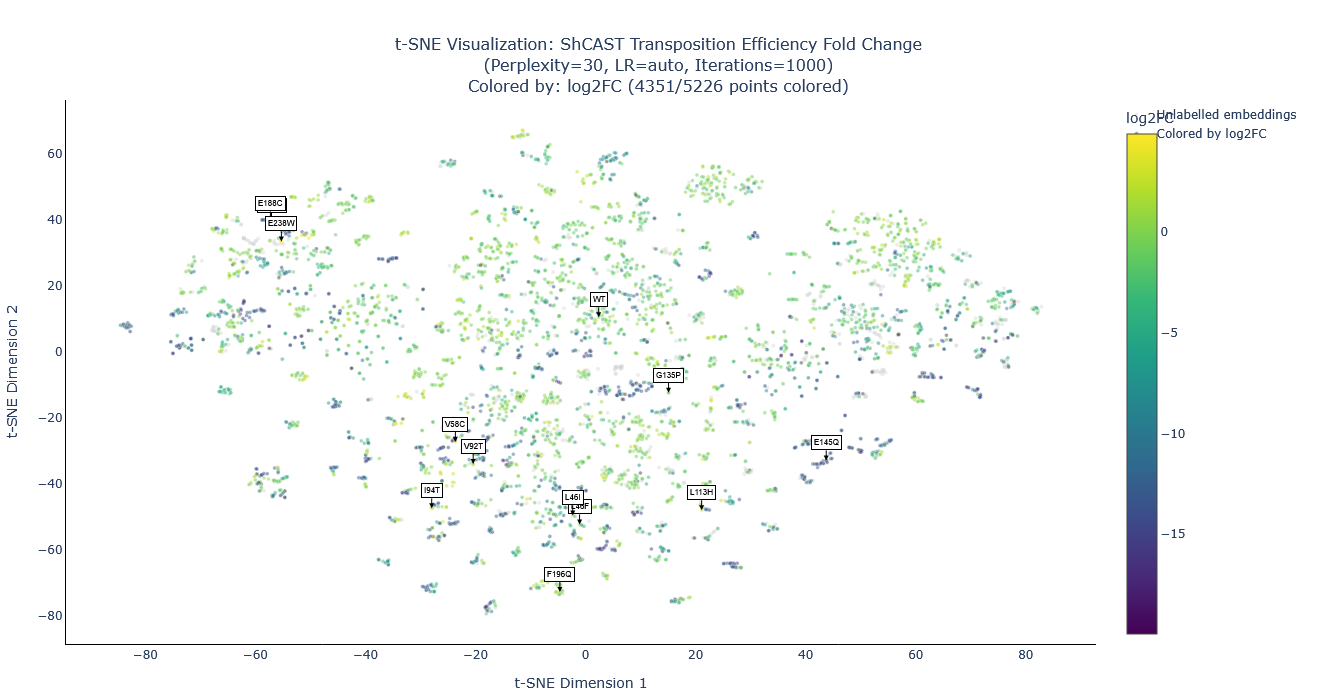

Static plot saved to: assets/tsne_visualization_activity.svg
Interactive HTML saved to: assets/tsne_visualization_activity.html


In [7]:
visualize_embeddings_tsne(
    '../1_Generate-embeddings/assets/ShCAST_emb',
    perplexity=30,
    learning_rate="auto",
    n_iterations=1000,
    fontsize=0,
    text_alpha=0,
    csv_path="assets/TnsC_activity.csv",
    name_column="Variant",
    value_column="log2FC",
    output_path="assets/tsne_visualization_activity.svg",
    output_html="assets/tsne_visualization_activity.html",
    fig_title="ShCAST Transposition Efficiency Fold Change",
    label_subset=label_subset,
    exclude_labels=exclude_subset,
    marker_size=4,
    colored_marker_alpha=0.5
)

### Mutations of interest

Treating 'of_interest' as categorical data
Found 71 matches between embeddings and CSV data out of 5226 total embeddings
Added 13 label annotations to the plot
t-SNE coordinates saved to: assets/tsne_visualization_mutations_of_interest.csv


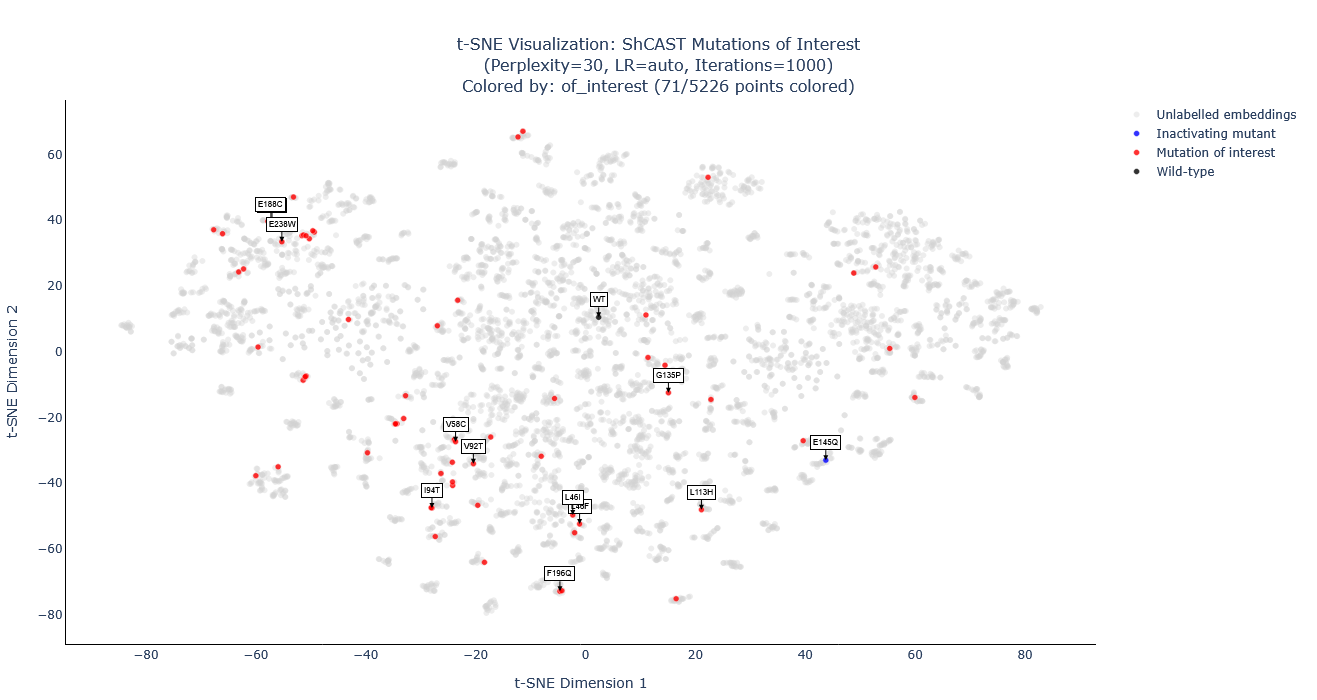

Static plot saved to: assets/tsne_visualization_mutations_of_interest.svg
Interactive HTML saved to: assets/tsne_visualization_mutations_of_interest.html


In [5]:
visualize_embeddings_tsne(
    '../1_Generate-embeddings/assets/ShCAST_emb',
    perplexity=30,
    learning_rate="auto",
    n_iterations=1000,
    fontsize=0,
    text_alpha=0,
    csv_path="assets/TnsC_activity_of_interest.csv",
    name_column="Variant",
    value_column="of_interest",
    output_path="assets/tsne_visualization_mutations_of_interest.svg",
    output_html="assets/tsne_visualization_mutations_of_interest.html",
    fig_title="ShCAST Mutations of Interest",
    label_subset=label_subset,
    exclude_labels=exclude_subset,
    categorical_colorscale=['blue', 'red', 'black'],
    marker_size=6,
    #colored_marker_alpha=0.4
)